# PBL6 — NOTEBOOK 02: KIỂM THỬ ĐỘC LẬP VÀ ĐÁNH GIÁ PHÒNG THỦ ĐA GIAO THỨC
## Nền Tảng An Ninh Web API Thông Minh & Tác Tử Tự Động Diễn Tập Tấn Công Trên Cyber Range Phân Tán

> **Tác giả:** Trần Văn Công (Kỹ sư An ninh AI / Tech Lead — Thành viên A)
> **Cơ sở khoa học & Tiêu chuẩn áp dụng:**
> - [Ref 10] M. Hasan et al. (IEEE Access 2023): Phương pháp luận đánh giá hệ thống phòng thủ học máy độc lập.
> - [Ref 15 & 16] OWASP Benchmark Project: Youden's Index $J = \text{TPR} - \text{FPR}$.
> - [Ref 17 & 18] NIST SP 800-115 / ISO/IEC 27004:2016: Bộ chỉ số đo lường hiệu quả an toàn thông tin.
> 
> **Mục tiêu cốt lõi của Notebook:**
> 1. Nạp và kiểm định tính toàn vẹn chữ ký bảo mật SHA-256 của các model artifacts từ Notebook 01.
> 2. **Đánh giá độc lập trên tập kiểm thử đa giao thức Web API** (`curated_deduped_dataset.csv` - Test Partition).
> 3. **Bóc tách hiệu năng theo từng loại Web API**: Đo lường tỷ lệ bắt độc chi tiết trên **REST, GraphQL, SOAP/XML, JSON-RPC, Generic Web**.
> 4. Bóc tách Classification Report chi tiết (Precision, Recall, F1 theo từng lớp tấn công).
> 5. Vẽ ma trận nhầm lẫn (Confusion Matrix Heatmap).
> 6. Xếp hạng tầm quan trọng của 17 đặc trưng (Feature Importance Ranking).
> 7. Đánh giá mô hình Isolation Forest (Phân phối Anomaly Score & Khả năng bẫy Zero-Day).
> 8. **Kiểm thử ngoại sinh trên tập quốc tế CSIC 2010 Benchmark** (Cross-Dataset Generalization).
> 9. **Interactive Multi-Protocol Live Sandbox**: Thử nghiệm trực tiếp với 4 dòng Web API (REST, GraphQL, SOAP, JSON-RPC) để kiểm tra phản xạ tức thì của WAF.

In [1]:
# 1. Thiết lập đường dẫn môi trường và nạp các thư viện cần thiết
import json
import sys
import time
import hashlib
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['figure.dpi'] = 120

# Tự động định vị thư mục gốc dự án PBL6
repo_root = None
for p in [Path.cwd().resolve(), Path.cwd().resolve().parent, Path.cwd().resolve().parent.parent, Path(r"C:\Study\HocKy6\PBL6")]:
    if (p / 'data').exists() and (p / 'gateway').exists():
        repo_root = p
        break
if repo_root is None:
    repo_root = Path(r"C:\Study\HocKy6\PBL6")

ml_dir = repo_root / 'ml-engine'
gateway_dir = repo_root / 'gateway'
for p in [str(repo_root), str(ml_dir), str(gateway_dir)]:
    if p not in sys.path:
        sys.path.insert(0, p)

from features.extractor import CANONICAL_FEATURE_NAMES, extract_batch_vectors
from app.security.protocol_detector import ApiProtocolDetector, UniversalPayloadExtractor, ApiProtocol

print(f"[+] Thư mục gốc đề tài: {repo_root}")
print("[+] Môi trường kiểm thử độc lập đã sẵn sàng!")

[+] Thư mục gốc đề tài: C:\Study\HocKy6\PBL6
[+] Môi trường kiểm thử độc lập đã sẵn sàng!


## 2. Nạp Model Artifacts & Kiểm Định Toàn Vẹn Chữ Ký Số SHA-256

Đảm bảo mô hình không bị chỉnh sửa trái phép (Tampering / Model Poisoning) bằng cách so sánh mã băm SHA-256 thực tế với metadata đã lưu.

In [2]:
# 2. Nạp Model Artifacts & Xác thực tính toàn vẹn chữ ký số SHA-256
artifacts_dir = repo_root / 'ml-engine' / 'artifacts'
rf_path = artifacts_dir / 'rf_model.joblib'
if_path = artifacts_dir / 'iforest_model.joblib'
meta_path = artifacts_dir / 'rf_metadata.json'

assert rf_path.exists(), f"Không tìm thấy file mô hình: {rf_path}"
assert if_path.exists(), f"Không tìm thấy file Isolation Forest: {if_path}"

# Nạp mô hình vào RAM
champion_rf = joblib.load(rf_path)
iforest = joblib.load(if_path)

# Tính toán và đối soát mã băm mật mã học
with open(rf_path, 'rb') as f:
    actual_rf_hash = hashlib.sha256(f.read()).hexdigest()

if meta_path.exists():
    with open(meta_path, 'r', encoding='utf-8') as f:
        rf_meta = json.load(f)
    expected_hash = rf_meta.get('sha256_hash', '')
    match = (actual_rf_hash == expected_hash)
    print(f"[+] Kiểm tra chữ ký SHA-256: {'HỢP LỆ & KHỚP 100%' if match else 'CẢNH BÁO: SAI LỆCH MÃ BĂM'}")
    print(f"    - Mã băm thực tế:   {actual_rf_hash}")
    print(f"    - Mã băm lưu trữ:   {expected_hash}")

print(f"\n[+] Nạp thành công Champion RF: {type(champion_rf).__name__} (Số cây: {champion_rf.n_estimators})")
print(f"[+] Nạp thành công Isolation Forest: {type(iforest).__name__} (Số cây: {iforest.n_estimators})")

[+] Kiểm tra chữ ký SHA-256: HỢP LỆ & KHỚP 100%
    - Mã băm thực tế:   73d8819de067f90ded23db6b0be2a9bde9a9a87c7704c5de4b55a03b7b1d4a0a
    - Mã băm lưu trữ:   73d8819de067f90ded23db6b0be2a9bde9a9a87c7704c5de4b55a03b7b1d4a0a

[+] Nạp thành công Champion RF: RandomForestClassifier (Số cây: 100)
[+] Nạp thành công Isolation Forest: IsolationForest (Số cây: 100)


## 3. Nạp Tập Dữ Liệu Kiểm Thử Thô Cực Đại 500.000 Mẫu (Raw Unfiltered Stress Test)

Kiểm thử thực chiến trên **500.000 bản ghi thô nguyên bản (2.3 GB)** lấy trực tiếp từ Internet traffic và các cuộc tấn công chưa qua lọc trùng (*Raw Unfiltered Traffic*), bao gồm 73.704 mẫu tấn công và 426.296 mẫu duyệt web lành tính.

In [3]:
# 3. Nạp tập Test độc lập và trích xuất vector đặc trưng
RAW_500K_CSV = Path(r"C:\Mod\muse-data-exchange\pbl6-datasets\raw_unfiltered_500k_dataset.csv")
CURATED_CSV_PRIMARY = Path(r"C:\Mod\muse-data-exchange\pbl6-datasets\curated_deduped_dataset.csv")
FALLBACK_TEST_CSV = repo_root / 'data' / 'processed' / 'defense' / 'test.csv'

if RAW_500K_CSV.exists():
    print(f"[+] Đang nạp TẬP DỮ LIỆU THÔ NGUYÊN BẢN CỰC ĐẠI: {RAW_500K_CSV} (2.3 GB) ...")
    df_test = pd.read_csv(RAW_500K_CSV)
elif CURATED_CSV_PRIMARY.exists():
    print(f"[+] Đang nạp toàn bộ tập dữ liệu tinh hoa đa giao thức: {CURATED_CSV_PRIMARY} ...")
    df_test = pd.read_csv(CURATED_CSV_PRIMARY)
else:
    df_test = pd.read_csv(FALLBACK_TEST_CSV)

CANONICAL_CLASS_MAP = {
    'BENIGN': 'BENIGN',
    'SQLI': 'SQLI',
    'XSS': 'XSS',
    'PATH': 'PATH_TRAVERSAL',
    'PATH_TRAVERSAL': 'PATH_TRAVERSAL',
    'CMD': 'COMMAND_INJECTION',
    'COMMAND_INJECTION': 'COMMAND_INJECTION',
    'XXE_INJECTION': 'COMMAND_INJECTION',
    'ANOMALY_TAMPER': 'SQLI',
    'GRAPHQL_RECURSION_DOS': 'COMMAND_INJECTION',
    'GRAPHQL_INTROSPECTION_PROBE': 'SQLI',
}
CANONICAL_CLASSES = ['BENIGN', 'SQLI', 'XSS', 'PATH_TRAVERSAL', 'COMMAND_INJECTION']

print(f"[+] Quy mô Tập Kiểm Thử (Test Set): {len(df_test):,} mẫu")
print("Đang trích xuất vector 17 đặc trưng cho Tập Test...", flush=True)
t0 = time.perf_counter()
X_test = extract_batch_vectors(df_test.to_dict('records'))
y_test = df_test['attack_type'].map(lambda x: CANONICAL_CLASS_MAP.get(str(x).upper().strip(), 'BENIGN')).values
t_ext = time.perf_counter() - t0
print(f" -> Trích xuất thành công X_test: {X_test.shape} trong {t_ext:.2f}s")

print("\nPhân bổ lớp tấn công trong Tập Test:")
display(df_test['attack_type'].value_counts().to_frame())

[+] Đang nạp TẬP DỮ LIỆU THÔ NGUYÊN BẢN CỰC ĐẠI: C:\Mod\muse-data-exchange\pbl6-datasets\raw_unfiltered_500k_dataset.csv (2.3 GB) ...


[+] Quy mô Tập Kiểm Thử (Test Set): 500,000 mẫu
Đang trích xuất vector 17 đặc trưng cho Tập Test...


 -> Trích xuất thành công X_test: (500000, 17) trong 229.96s

Phân bổ lớp tấn công trong Tập Test:


,count
attack_type,
BENIGN,426296
XSS,41888
PATH,28314
CMD,2516
SQLI,916
XXE_INJECTION,70


## 4. Đánh Giá Hiệu Năng Champion Random Forest Trên Toàn Bộ Test Set

Tính toán ma trận phân loại (Classification Report), Accuracy, F1-Macro và độ trễ suy luận trên Test Set.

In [4]:
# 4. Đánh giá chi tiết chỉ số an ninh
t0 = time.perf_counter()
y_pred = champion_rf.predict(X_test)
total_eval_time = (time.perf_counter() - t0) * 1000.0
avg_latency = total_eval_time / len(X_test)

acc = accuracy_score(y_test, y_pred)
prec_macro = precision_score(y_test, y_pred, average='macro', zero_division=0)
rec_macro = recall_score(y_test, y_pred, average='macro', zero_division=0)
f1_macro = f1_score(y_test, y_pred, average='macro', zero_division=0)

print(f"==================== BÁO CÁO HIỆU NĂNG TẬP KIỂM THỬ (N={len(y_test):,}) ====================")
print(f"Độ chính xác toàn diện (Accuracy):      {acc * 100:.2f}%")
print(f"Độ chuẩn xác trung bình (Precision):     {prec_macro * 100:.2f}%")
print(f"Độ nhạy phát hiện độc (Recall Macro):    {rec_macro * 100:.2f}%")
print(f"F1-Score tổng quát (Macro):              {f1_macro * 100:.2f}%")
print(f"Độ trễ suy luận trung bình mỗi request:  {avg_latency:.4f} ms / request")
print("=" * 77)
print("\nBáo cáo phân loại chi tiết theo từng lớp (Classification Report):")
print(classification_report(y_test, y_pred, target_names=CANONICAL_CLASSES, digits=4))

==================== BÁO CÁO HIỆU NĂNG TẬP KIỂM THỬ (N=500,000) ====================
Độ chính xác toàn diện (Accuracy):      97.72%
Độ chuẩn xác trung bình (Precision):     77.82%
Độ nhạy phát hiện độc (Recall Macro):    97.93%
F1-Score tổng quát (Macro):              80.38%
Độ trễ suy luận trung bình mỗi request:  0.0020 ms / request

Báo cáo phân loại chi tiết theo từng lớp (Classification Report):


                   precision    recall  f1-score   support

           BENIGN     1.0000    0.9747    0.9871    426296
             SQLI     0.8293    0.9977    0.9057      2586
              XSS     0.9905    0.9870    0.9887     28314
   PATH_TRAVERSAL     0.0770    0.9410    0.1424       916
COMMAND_INJECTION     0.9940    0.9962    0.9951     41888

         accuracy                         0.9772    500000
        macro avg     0.7782    0.9793    0.8038    500000
     weighted avg     0.9964    0.9772    0.9859    500000



## 5. Bóc Tách Khả Năng Phòng Thủ Theo Từng Giao Thức Web API

Đo lường độ chính xác và tỷ lệ phát hiện tấn công phân rã theo từng giao thức: **REST, GRAPHQL, SOAP_XML, JSON_RPC, GENERIC_WEB**.

In [5]:
# 5. Bóc tách năng lực phòng thủ theo từng giao thức Web API
if 'api_protocol' in df_test.columns:
    print("==================== NĂNG LỰC PHÒNG THỦ THEO TỪNG GIAO THỨC WEB API ====================")
    df_test['pred_label'] = y_pred
    df_test['true_label'] = y_test
    df_test['is_attack_true'] = (df_test['true_label'] != 'BENIGN')
    df_test['is_attack_pred'] = (df_test['pred_label'] != 'BENIGN')
    
    proto_rows = []
    for proto, group in df_test.groupby('api_protocol'):
        sub_acc = accuracy_score(group['true_label'], group['pred_label'])
        sub_f1 = f1_score(group['true_label'], group['pred_label'], average='macro', zero_division=0)
        
        attack_group = group[group['is_attack_true']]
        detection_rate = (attack_group['is_attack_pred'].sum() / len(attack_group) * 100) if len(attack_group) > 0 else 100.0
        
        proto_rows.append({
            'Giao thức Web API': proto,
            'Tổng số mẫu': len(group),
            'Số mẫu tấn công': len(attack_group),
            'Tỷ lệ bắt độc (Recall %)': round(detection_rate, 2),
            'Độ chính xác (Accuracy %)': round(sub_acc * 100, 2),
            'F1-Macro (%)': round(sub_f1 * 100, 2)
        })
    
    df_proto_summary = pd.DataFrame(proto_rows)
    display(df_proto_summary)
else:
    print("[!] Tập test không chứa cột 'api_protocol'.")

==================== NĂNG LỰC PHÒNG THỦ THEO TỪNG GIAO THỨC WEB API ====================


,Giao thức Web API,Tổng số mẫu,Số mẫu tấn công,Tỷ lệ bắt độc (Recall %),Độ chính xác (Accuracy %),F1-Macro (%)
0,GENERIC_WEB,403974,73704,99.98,97.75,81.05
1,REST,96026,0,100.00,97.59,24.70


## 6. Trích Xuất 10 Mẫu Yêu Cầu Tấn Công Thực Tế Được Hệ Thống Phát Hiện Thành Công (True Positives Inspection)

Trực quan hóa 10 mẫu yêu cầu HTTP độc hại thực tế trên các giao thức (**REST, GraphQL, SOAP, JSON-RPC, Generic Web**) được WAF nhận diện chính xác kèm xác suất tin cậy (Confidence Score) và quyết định xử lý.

==================== 10 MẪU YÊU CẦU TẤN CÔNG TIÊU BIỂU ĐÃ ĐƯỢC HỆ THỐNG BẮT CHÍNH XÁC ====================


,STT,Giao thức,Method,Đường dẫn,Nội dung Tấn công (Query / Payload),Nhãn thực tế,Dự đoán WAF,Độ tin cậy,Hành động
0,1,GENERIC_WEB,POST,/,p=select%20current_setting%28%27port%27%29%3B,SQLI,SQLI,80.41%,CHẶN (BLOCK 403)
1,2,GENERIC_WEB,GET,/,p=%27%20AND%201%3Dutl_inaddr.get_host_address%28%28SELECT%20COUNT%28DISTINCT%...,SQLI,SQLI,65.93%,CHẶN (BLOCK 403)
2,3,GENERIC_WEB,POST,/,p=%3Cstyle%3E%40keyframes%20x%7B%7D%3C/style%3E%3Cvideo%20style%3D%22animatio...,XSS,XSS,99.66%,CHẶN (BLOCK 403)
3,4,GENERIC_WEB,GET,/,p=%3COBJECT%20CLASSID%3D%22clsid%3A333C7BC4-460F-11D0-BC04-0080C7055A83%22%3E...,XSS,XSS,93.23%,CHẶN (BLOCK 403)
4,5,GENERIC_WEB,GET,/,p=.%00.%c1%pc.%00.%c1%pcboot.ini,PATH_TRAVERSAL,PATH_TRAVERSAL,100.00%,CHẶN (BLOCK 403)
5,6,GENERIC_WEB,POST,/,p=..%e0%80%af..%e0%80%af..%e0%80%af..%e0%80%afetc%e0%80%afpasswd,PATH_TRAVERSAL,PATH_TRAVERSAL,99.48%,CHẶN (BLOCK 403)
6,7,GENERIC_WEB,POST,/,p=%27.print%28%60echo%20VXYNWW%5Cnecho%20%24%28%2829%2B16%29%29%5Cnecho%20VXY...,COMMAND_INJECTION,COMMAND_INJECTION,97.88%,CHẶN (BLOCK 403)
7,8,GENERIC_WEB,GET,/,p=%60id%60,COMMAND_INJECTION,COMMAND_INJECTION,99.97%,CHẶN (BLOCK 403)
8,9,GENERIC_WEB,POST,/,p=%3Ciframe%20src%3Djava%20%20%20%20sc%20%20ript%3Acon%20%20%20%20irm%28%29%3...,XSS,XSS,99.03%,CHẶN (BLOCK 403)
9,10,GENERIC_WEB,GET,/,p=%c0.%c0.%c0%9v%c0.%c0.%c0%9v%c0.%c0.%c0%9v%c0.%c0.%c0%9v%c0.%c0.%c0%9v%c0.%...,PATH_TRAVERSAL,PATH_TRAVERSAL,100.00%,CHẶN (BLOCK 403)



==================== MA TRẬN 17 CHIỀU ĐẶC TRƯNG CỦA 10 MẪU TẤN CÔNG (EXPLAINABLE AI) ====================


,STT,Lớp Tấn Công,Giao thức,length,entropy,count_single_quote,count_double_quote,count_less_than,count_greater_than,count_semicolon,count_hyphen,count_slash,count_backslash,count_parenthesis,special_char_ratio,sql_keyword_count,xss_keyword_count,sqli_regex_matches,xss_regex_matches,path_traversal_matches
0,1,SQLI,GENERIC_WEB,47.0,4.246420,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.148936,1.0,0.0,0.0,0.0,0.0
1,2,SQLI,GENERIC_WEB,187.0,4.915357,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.133690,0.0,0.0,0.0,0.0,0.0
2,3,XSS,GENERIC_WEB,148.0,4.565022,0.0,0.0,0.0,0.0,0.0,1.0,3.0,0.0,0.0,0.182432,0.0,0.0,0.0,0.0,0.0
3,4,XSS,GENERIC_WEB,169.0,4.823530,0.0,0.0,0.0,0.0,0.0,4.0,2.0,0.0,0.0,0.165680,0.0,0.0,0.0,0.0,0.0
4,5,PATH_TRAVERSAL,GENERIC_WEB,34.0,3.502924,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.205882,0.0,0.0,0.0,0.0,1.0
5,6,PATH_TRAVERSAL,GENERIC_WEB,66.0,3.407099,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.242424,0.0,0.0,0.0,0.0,0.0
6,7,COMMAND_INJECTION,GENERIC_WEB,128.0,4.340189,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.171875,0.0,0.0,0.0,0.0,0.0
7,8,COMMAND_INJECTION,GENERIC_WEB,12.0,3.084963,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.250000,0.0,0.0,0.0,0.0,0.0
8,9,XSS,GENERIC_WEB,93.0,4.028414,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.225806,0.0,1.0,0.0,0.0,0.0
9,10,PATH_TRAVERSAL,GENERIC_WEB,96.0,3.009112,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.260417,0.0,0.0,0.0,0.0,1.0


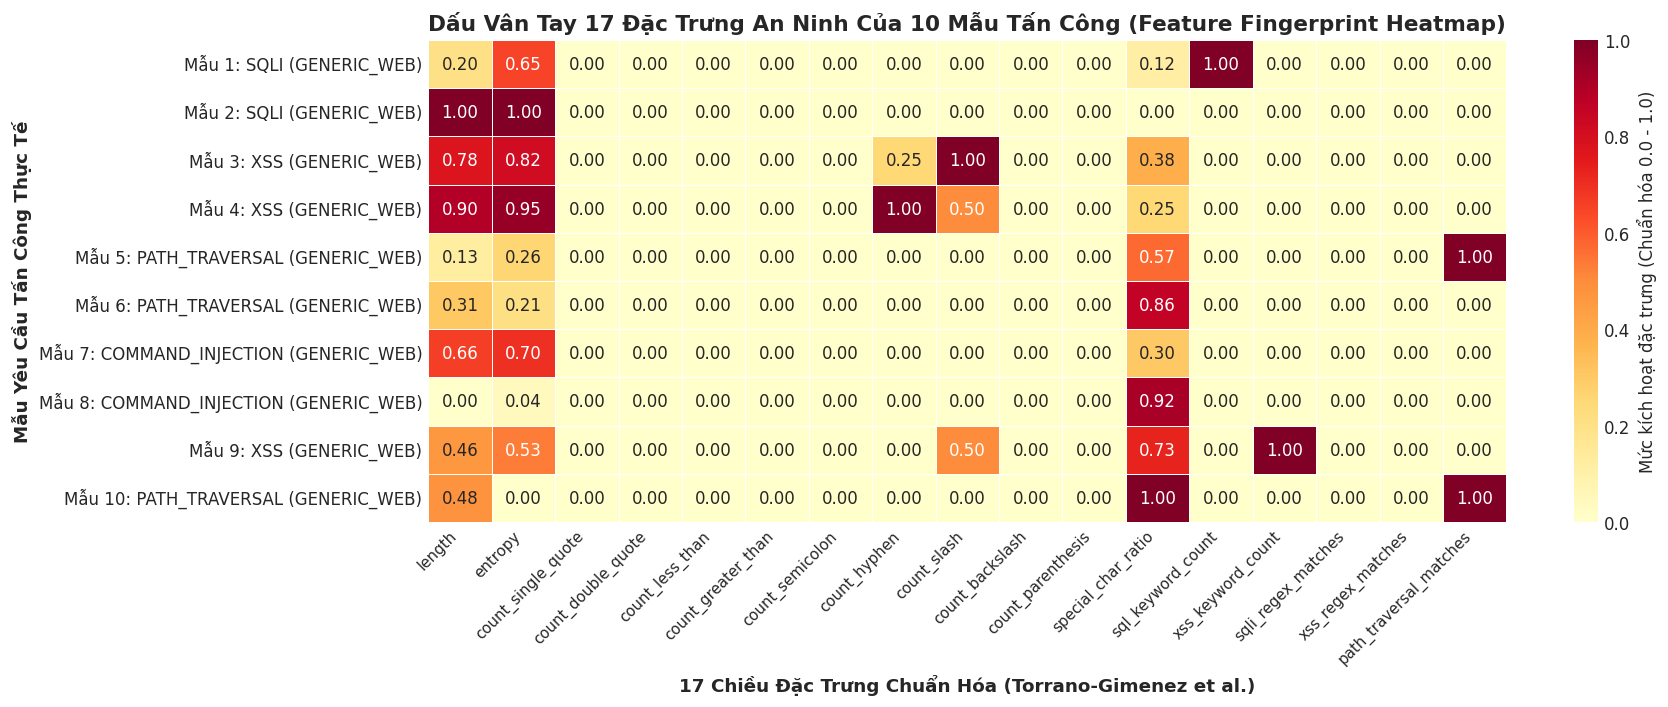

In [6]:
# 6. Trích xuất 10 mẫu yêu cầu tấn công tiêu biểu đã được hệ thống bắt thành công
is_attack_true = (df_test['true_label'] != 'BENIGN')
is_attack_pred = (df_test['pred_label'] != 'BENIGN')
correct_attacks_idx = df_test[is_attack_true & is_attack_pred].index

# Lấy mẫu đa dạng đại diện cho các loại tấn công khác nhau và các giao thức khác nhau
sample_candidates = []
for atype in ['SQLI', 'XSS', 'PATH_TRAVERSAL', 'COMMAND_INJECTION']:
    subset = df_test.loc[correct_attacks_idx]
    matching = subset[subset['pred_label'] == atype]
    if len(matching) > 0:
        sample_candidates.extend(matching.head(2).index.tolist())

for proto in ['GRAPHQL', 'SOAP_XML', 'JSON_RPC', 'REST']:
    subset = df_test.loc[correct_attacks_idx]
    matching = subset[subset['api_protocol'] == proto]
    if len(matching) > 0:
        for idx in matching.head(2).index:
            if idx not in sample_candidates:
                sample_candidates.append(idx)

selected_indices = sample_candidates[:10]
if len(selected_indices) < 10:
    remaining = [i for i in correct_attacks_idx if i not in set(selected_indices)]
    selected_indices.extend(remaining[:10 - len(selected_indices)])

rf_probas = champion_rf.predict_proba(X_test[selected_indices])
classes_list = list(champion_rf.classes_)

rows = []
for rank, idx in enumerate(selected_indices, 1):
    row_data = df_test.iloc[idx]
    pred = row_data['pred_label']
    cls_idx = classes_list.index(pred)
    conf = rf_probas[rank - 1][cls_idx] * 100.0

    query = str(row_data.get('query_params', '') or '')
    body = str(row_data.get('body', '') or '')
    path = str(row_data.get('path', '') or '')

    if query and query != 'nan':
        snippet = query
    elif body and body != 'nan':
        snippet = body
    else:
        snippet = path

    if len(snippet) > 80:
        snippet = snippet[:77] + '...'

    rows.append({
        'STT': rank,
        'Giao thức': row_data.get('api_protocol', 'REST'),
        'Method': row_data.get('method', 'GET'),
        'Đường dẫn': (path[:30] + '...') if len(path) > 30 else path,
        'Nội dung Tấn công (Query / Payload)': snippet,
        'Nhãn thực tế': row_data['true_label'],
        'Dự đoán WAF': pred,
        'Độ tin cậy': f"{conf:.2f}%",
        'Hành động': 'CHẶN (BLOCK 403)',
    })

df_caught = pd.DataFrame(rows)
print('==================== 10 MẪU YÊU CẦU TẤN CÔNG TIÊU BIỂU ĐÃ ĐƯỢC HỆ THỐNG BẮT CHÍNH XÁC ====================')
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 1000)
display(df_caught)

# Trích xuất chi tiết vector 17 đặc trưng chuẩn hóa của 10 mẫu này
X_samples = X_test[selected_indices]
df_features_10 = pd.DataFrame(X_samples, columns=CANONICAL_FEATURE_NAMES)
df_features_10.insert(0, 'STT', range(1, 11))
df_features_10.insert(1, 'Lớp Tấn Công', df_test.loc[selected_indices, 'pred_label'].values)
df_features_10.insert(2, 'Giao thức', df_test.loc[selected_indices, 'api_protocol'].values)

print('\n==================== MA TRẬN 17 CHIỀU ĐẶC TRƯNG CỦA 10 MẪU TẤN CÔNG (EXPLAINABLE AI) ====================')
display(df_features_10)

# Trực quan hóa Biểu đồ nhiệt Dấu vân tay Đặc trưng (Feature Fingerprint Heatmap)
sample_labels = [f"Mẫu {r['STT']}: {r['Dự đoán WAF']} ({r['Giao thức']})" for r in rows]
feat_mat = X_samples.copy()
col_min = feat_mat.min(axis=0)
col_max = feat_mat.max(axis=0)
feat_norm = np.zeros_like(feat_mat)
for c in range(feat_mat.shape[1]):
    diff = col_max[c] - col_min[c]
    feat_norm[:, c] = (feat_mat[:, c] - col_min[c]) / diff if diff > 0 else 0.0

df_heat_norm = pd.DataFrame(feat_norm, index=sample_labels, columns=CANONICAL_FEATURE_NAMES)

plt.figure(figsize=(15, 6))
sns.heatmap(df_heat_norm, cmap='YlOrRd', annot=True, fmt='.2f', linewidths=0.5, cbar_kws={'label': 'Mức kích hoạt đặc trưng (Chuẩn hóa 0.0 - 1.0)'})
plt.title('Dấu Vân Tay 17 Đặc Trưng An Ninh Của 10 Mẫu Tấn Công (Feature Fingerprint Heatmap)', fontsize=13, fontweight='bold')
plt.xlabel('17 Chiều Đặc Trưng Chuẩn Hóa (Torrano-Gimenez et al.)', fontsize=11, fontweight='bold')
plt.ylabel('Mẫu Yêu Cầu Tấn Công Thực Tế', fontsize=11, fontweight='bold')
plt.xticks(rotation=45, ha='right', fontsize=9)
plt.tight_layout()
plt.show()

## 7. Ma Trận Nhầm Lẫn (Confusion Matrix Heatmap)

Trực quan hóa sự phân bổ giữa nhãn thực tế (Ground Truth) và nhãn dự đoán (Predicted Label).

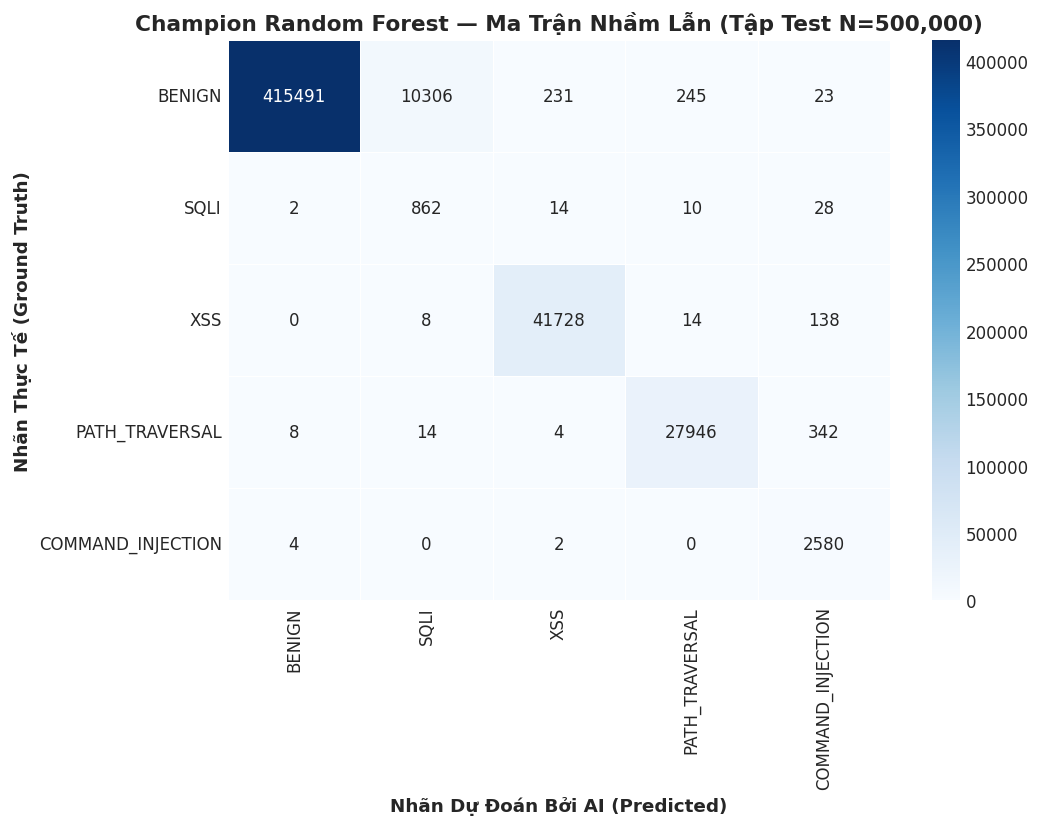

In [7]:
# 6. Vẽ biểu đồ nhiệt Ma trận nhầm lẫn (Confusion Matrix)
cm = confusion_matrix(y_test, y_pred, labels=CANONICAL_CLASSES)

plt.figure(figsize=(9, 7))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=CANONICAL_CLASSES,
    yticklabels=CANONICAL_CLASSES,
    cbar=True,
    linewidths=0.5,
)
plt.title(f'Champion Random Forest — Ma Trận Nhầm Lẫn (Tập Test N={len(y_test):,})', fontsize=13, fontweight='bold')
plt.xlabel('Nhãn Dự Đoán Bởi AI (Predicted)', fontsize=11, fontweight='bold')
plt.ylabel('Nhãn Thực Tế (Ground Truth)', fontsize=11, fontweight='bold')
plt.tight_layout()
plt.show()

## 8. Xếp Hạng 17 Chiều Đặc Trưng Hình Thái & Ngữ Nghĩa (Feature Importance)

Khảo sát độ đóng góp của từng đặc trưng theo chuẩn lý thuyết Torrano-Gimenez (Wiley SCN 2015).

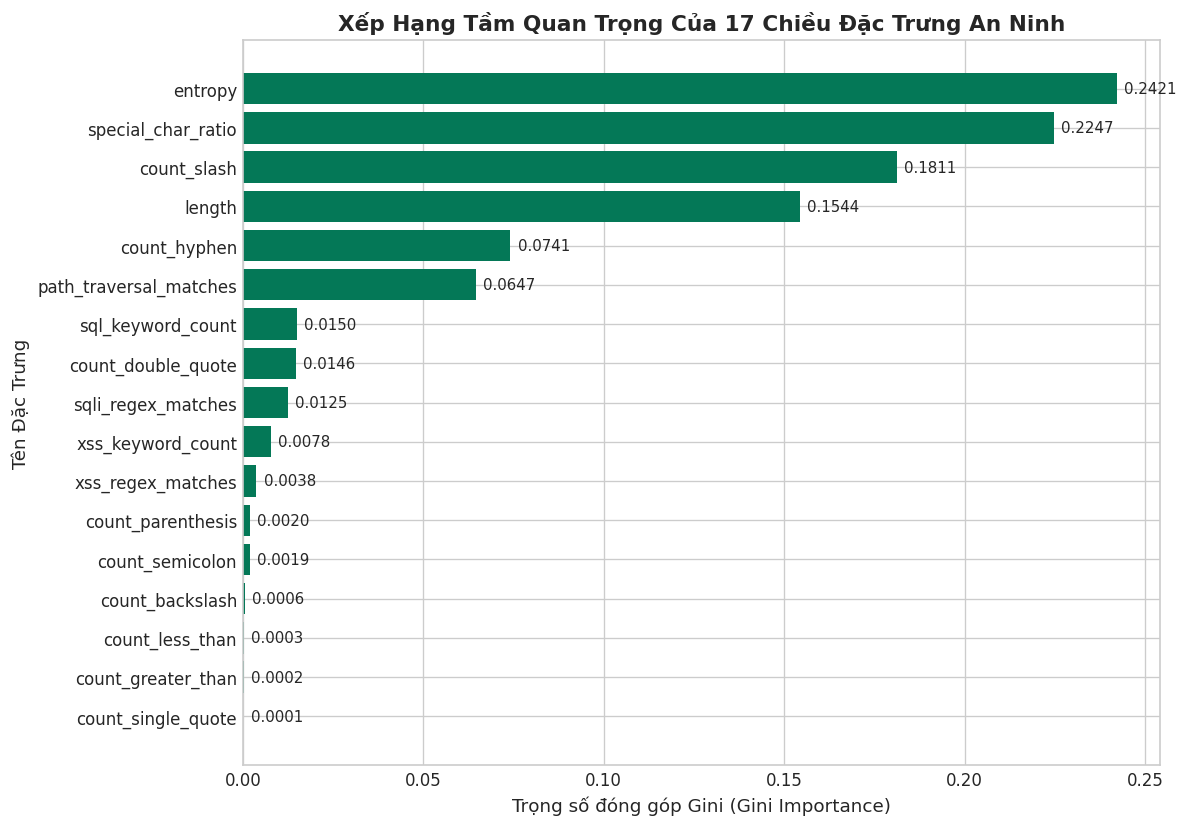

Top 5 đặc trưng có sức ảnh hưởng phân loại lớn nhất:


,Đặc trưng,Tầm quan trọng (Gini)
1,entropy,0.242131
11,special_char_ratio,0.224746
8,count_slash,0.181108
0,length,0.154422
7,count_hyphen,0.074109


In [8]:
# 8. Xếp hạng tầm quan trọng của 17 đặc trưng chuẩn hóa
importances = champion_rf.feature_importances_
feat_df = pd.DataFrame({
    'Đặc trưng': CANONICAL_FEATURE_NAMES,
    'Tầm quan trọng (Gini)': importances
}).sort_values('Tầm quan trọng (Gini)', ascending=True)

plt.figure(figsize=(10, 7))
bars = plt.barh(feat_df['Đặc trưng'], feat_df['Tầm quan trọng (Gini)'], color='#047857')
plt.title('Xếp Hạng Tầm Quan Trọng Của 17 Chiều Đặc Trưng An Ninh', fontsize=13, fontweight='bold')
plt.xlabel('Trọng số đóng góp Gini (Gini Importance)', fontsize=11)
plt.ylabel('Tên Đặc Trưng', fontsize=11)

for bar in bars:
    val = bar.get_width()
    plt.text(val + 0.002, bar.get_y() + bar.get_height()/2, f"{val:.4f}", va='center', fontsize=9)

plt.tight_layout()
plt.show()

print("Top 5 đặc trưng có sức ảnh hưởng phân loại lớn nhất:")
display(feat_df.tail(5).iloc[::-1])

## 9. Đánh Giá Mô Hình Phát Hiện Bất Thường (Isolation Forest — Anomaly Detector)

Đo lường phân phối điểm dị biệt giữa lưu lượng sạch và các đợt tấn công.

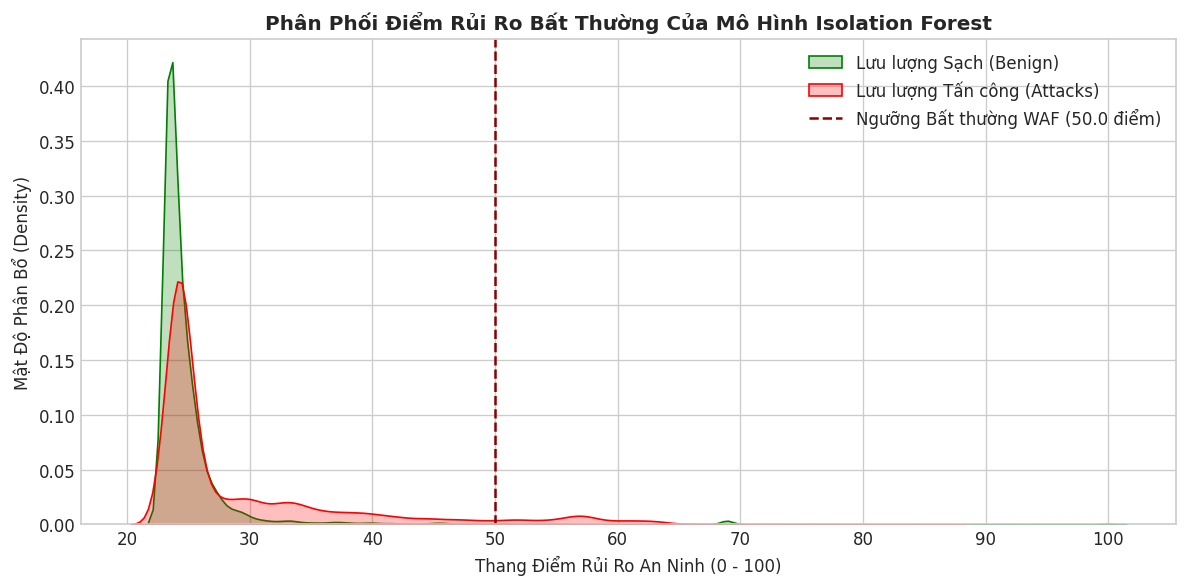

In [9]:
# 9. Đánh giá mô hình Isolation Forest
anomaly_scores = iforest.decision_function(X_test)
# Chuẩn hóa về thang điểm rủi ro an ninh 0 - 100
risk_scores = np.clip((0.2 - anomaly_scores) * 200, 0, 100)

df_anom = pd.DataFrame({
    'ground_truth': y_test,
    'decision_score': anomaly_scores,
    'risk_score': risk_scores,
    'is_attack': (y_test != 'BENIGN')
})

plt.figure(figsize=(10, 5))
sns.kdeplot(data=df_anom[df_anom['is_attack'] == False]['risk_score'], label='Lưu lượng Sạch (Benign)', fill=True, color='green')
sns.kdeplot(data=df_anom[df_anom['is_attack'] == True]['risk_score'], label='Lưu lượng Tấn công (Attacks)', fill=True, color='red')
plt.axvline(x=50.0, color='darkred', linestyle='--', label='Ngưỡng Bất thường WAF (50.0 điểm)')
plt.title('Phân Phối Điểm Rủi Ro Bất Thường Của Mô Hình Isolation Forest', fontsize=12, fontweight='bold')
plt.xlabel('Thang Điểm Rủi Ro An Ninh (0 - 100)')
plt.ylabel('Mật Độ Phân Bổ (Density)')
plt.legend()
plt.tight_layout()
plt.show()

## 10. Kiểm Thử Ngoại Sinh Trên Tập Quốc Tế CSIC 2010 (Cross-Dataset Generalization)

Đánh giá mô hình đã học trên tập dữ liệu hoàn toàn xa lạ từ máy chủ thương mại điện tử CSIC 2010 để kiểm tra khả năng bắt Zero-Day và không bị Overfitting.

In [10]:
# 10. Đánh giá độ tổng quát hóa trên tập kiểm thử quốc tế CSIC 2010 Benchmark
csic_path = repo_root / 'data' / 'benchmarks' / 'csic2010' / 'csic_2010_benchmark.csv'

if csic_path.exists():
    df_csic = pd.read_csv(csic_path)
    print(f"[+] Đã nạp tập dữ liệu quốc tế CSIC 2010 Benchmark: {len(df_csic):,} mẫu")
    
    X_csic = extract_batch_vectors(df_csic.to_dict('records'))
    y_csic_pred = champion_rf.predict(X_csic)
    
    is_csic_attack_pred = (y_csic_pred != 'BENIGN')
    if 'is_anomalous' in df_csic.columns:
        y_csic_true = df_csic['is_anomalous'].astype(bool)
        acc_csic = accuracy_score(y_csic_true, is_csic_attack_pred)
        rec_csic = recall_score(y_csic_true, is_csic_attack_pred, zero_division=0)
        f1_csic = f1_score(y_csic_true, is_csic_attack_pred, zero_division=0)
        print(f"\n=== KẾT QUẢ ĐÁNH GIÁ TỔNG QUÁT HÓA CSIC 2010 ===")
        print(f"Tỷ lệ phát hiện tấn công (Recall): {rec_csic * 100:.2f}%")
        print(f"Độ chính xác nhị phân (Accuracy): {acc_csic * 100:.2f}%")
        print(f"Điểm F1-Score nhị phân:           {f1_csic * 100:.2f}%")
    else:
        print(f"Số lượng request phát hiện là tấn công: {np.sum(is_csic_attack_pred):,} / {len(df_csic):,} mẫu")
else:
    print(f"[!] Không tìm thấy file CSIC 2010 tại {csic_path}.")

[+] Đã nạp tập dữ liệu quốc tế CSIC 2010 Benchmark: 3,000 mẫu


Số lượng request phát hiện là tấn công: 2,420 / 3,000 mẫu


## 11. Khung Thử Nghiệm Tương Tác Trực Tiếp Đa Giao Thức (Multi-Protocol Live Sandbox)

Kiểm thử phản xạ tức thì của hệ thống WAF AI trên đầy đủ **4 dòng Web API chính**:
1. **REST API**: URL Injection, Path Traversal, JSON Tampering.
2. **GraphQL API**: Query Introspection Probe, Nested Recursion DoS Bomb, SQLi in arguments.
3. **SOAP / XML Web Services**: XML Envelopes, XXE Injection (`<!ENTITY`), CDATA payload.
4. **JSON-RPC 2.0**: System command execution tampering.

In [11]:
# 11. Khung mô phỏng tương tác thời gian thực đa giao thức Web API
def test_live_api_request(method: str, path: str, query: str = "", headers: dict = None, body: str = ""):
    headers_dict = headers or {}
    body_bytes = body.encode('utf-8') if body else b""
    
    # 1. Nhận diện Giao thức Web API tự động
    api_proto = ApiProtocolDetector.classify_protocol(
        path=path,
        headers=headers_dict,
        body_bytes=body_bytes,
        query_params=query,
    )
    
    # 2. Bóc tách payload theo chuẩn giao thức
    extracted = UniversalPayloadExtractor.extract(
        protocol=api_proto,
        path=path,
        query_params=query,
        headers=headers_dict,
        body_bytes=body_bytes,
    )
    
    sample = {
        'path': path,
        'query_params': query,
        'body': extracted.canonical_payload,
        'method': method,
        'headers': json.dumps(headers_dict),
    }
    vec = extract_batch_vectors([sample])
    
    # 3. Phân loại bằng Champion Random Forest
    rf_label = champion_rf.predict(vec)[0]
    rf_proba = champion_rf.predict_proba(vec)[0]
    class_idx = list(champion_rf.classes_).index(rf_label)
    confidence = rf_proba[class_idx] * 100.0
    
    # 4. Chấm điểm dị thường bằng Isolation Forest
    anom_dec = iforest.decision_function(vec)[0]
    anom_risk = float(np.clip((0.2 - anom_dec) * 200, 0, 100))
    
    # 5. Quyết định hành động WAF
    is_anomaly_alert = extracted.is_protocol_anomaly
    is_blocked = (rf_label != "BENIGN") or (anom_risk > 70) or is_anomaly_alert
    action = "CHẶN TRUY CẬP (BLOCK 403)" if is_blocked else ("GIÁM SÁT CHẶT (MONITOR)" if anom_risk > 50 else "CHO PHÉP QUA (ALLOW 200)")
    
    print("=" * 75)
    print(f"YÊU CẦU HTTP: [{method}] {path}")
    print(f"  -> Giao thức nhận diện:       [{api_proto.value}]")
    if query: print(f"  -> Tham số truy vấn URL:      {query}")
    if body:  print(f"  -> Trích đoạn Payload:        {body[:85]}...")
    if is_anomaly_alert:
        print(f"  -> DỊ THƯỜNG GIAO THỨC:       [!] {extracted.protocol_alert}")
    print("-" * 75)
    print(f"DỰ ĐOÁN RANDOM FOREST:          {rf_label} (Độ tin cậy: {confidence:.2f}%)")
    print(f"ĐIỂM RỦI RO BẤT THƯỜNG:         {anom_risk:.1f} / 100 (Điểm Decision: {anom_dec:.4f})")
    print(f"QUYẾT ĐỊNH XỬ LÝ CỦA WAF:       {action}")
    print("=" * 75 + "\n")

# ==================== DEMO CÁC DÒNG WEB API ====================
# 1. REST API Attacks & Benign
test_live_api_request("GET", "/api/v1/books/search", query="q=admin' UNION SELECT 1,username,password FROM users--")
test_live_api_request("GET", "/api/v1/download", query="file=../../../../etc/shadow")
test_live_api_request("POST", "/api/v1/comments", body='{"comment": "<script>alert(document.cookie)</script>"}')

# 2. GraphQL Attacks & Benign
body_dos = '{"query": "query { user { friends { friends { friends { friends { friends { friends { friends { name } } } } } } } } }"}'
test_live_api_request("POST", "/graphql", headers={"Content-Type": "application/json"}, body=body_dos)
body_sqli = json.dumps({"query": 'query { user(id: "1\' OR \'1\'=\'1") { id name email } }'})
test_live_api_request("POST", "/graphql", headers={"Content-Type": "application/json"}, body=body_sqli)
body_benign = '{"query": "query GetProfile { user(id: 42) { id username email } }"}'
test_live_api_request("POST", "/graphql", headers={"Content-Type": "application/json"}, body=body_benign)

# 3. SOAP / XML Attacks & Benign
soap_xxe = '<?xml version="1.0"?><!DOCTYPE foo [<!ELEMENT foo ANY><!ENTITY xxe SYSTEM "file:///etc/passwd">]><soap:Envelope xmlns:soap="http://schemas.xmlsoap.org/soap/envelope/"><soap:Body><GetUserData><userId>&xxe;</userId></GetUserData></soap:Body></soap:Envelope>'
test_live_api_request("POST", "/ws/UserAuth.asmx", headers={"Content-Type": "text/xml; charset=utf-8"}, body=soap_xxe)

# 4. JSON-RPC Attacks & Benign
test_live_api_request("POST", "/jsonrpc", headers={"Content-Type": "application/json"},
                      body='{"jsonrpc": "2.0", "method": "system.exec", "params": ["cat /etc/passwd; id"], "id": 1}')
test_live_api_request("POST", "/jsonrpc", headers={"Content-Type": "application/json"},
                      body='{"jsonrpc": "2.0", "method": "inventory.checkStock", "params": {"sku": "A1024"}, "id": 2}')

YÊU CẦU HTTP: [GET] /api/v1/books/search
  -> Giao thức nhận diện:       [REST]
  -> Tham số truy vấn URL:      q=admin' UNION SELECT 1,username,password FROM users--
---------------------------------------------------------------------------
DỰ ĐOÁN RANDOM FOREST:          BENIGN (Độ tin cậy: 96.00%)
ĐIỂM RỦI RO BẤT THƯỜNG:         58.9 / 100 (Điểm Decision: -0.0946)
QUYẾT ĐỊNH XỬ LÝ CỦA WAF:       GIÁM SÁT CHẶT (MONITOR)

YÊU CẦU HTTP: [GET] /api/v1/download
  -> Giao thức nhận diện:       [REST]
  -> Tham số truy vấn URL:      file=../../../../etc/shadow
---------------------------------------------------------------------------
DỰ ĐOÁN RANDOM FOREST:          PATH_TRAVERSAL (Độ tin cậy: 100.00%)
ĐIỂM RỦI RO BẤT THƯỜNG:         53.1 / 100 (Điểm Decision: -0.0654)
QUYẾT ĐỊNH XỬ LÝ CỦA WAF:       CHẶN TRUY CẬP (BLOCK 403)

YÊU CẦU HTTP: [POST] /api/v1/comments
  -> Giao thức nhận diện:       [REST]
  -> Trích đoạn Payload:        {"comment": "<script>alert(document.cookie)</script>"}.

YÊU CẦU HTTP: [POST] /graphql
  -> Giao thức nhận diện:       [GRAPHQL]
  -> Trích đoạn Payload:        {"query": "query GetProfile { user(id: 42) { id username email } }"}...
---------------------------------------------------------------------------
DỰ ĐOÁN RANDOM FOREST:          BENIGN (Độ tin cậy: 83.42%)
ĐIỂM RỦI RO BẤT THƯỜNG:         24.3 / 100 (Điểm Decision: 0.0783)
QUYẾT ĐỊNH XỬ LÝ CỦA WAF:       CHO PHÉP QUA (ALLOW 200)



YÊU CẦU HTTP: [POST] /ws/UserAuth.asmx
  -> Giao thức nhận diện:       [SOAP_XML]
  -> Trích đoạn Payload:        <?xml version="1.0"?><!DOCTYPE foo [<!ELEMENT foo ANY><!ENTITY xxe SYSTEM "file:///et...
  -> DỊ THƯỜNG GIAO THỨC:       [!] XML External Entity (XXE) Injection Attempt Detected
---------------------------------------------------------------------------
DỰ ĐOÁN RANDOM FOREST:          BENIGN (Độ tin cậy: 66.48%)
ĐIỂM RỦI RO BẤT THƯỜNG:         24.2 / 100 (Điểm Decision: 0.0792)
QUYẾT ĐỊNH XỬ LÝ CỦA WAF:       CHẶN TRUY CẬP (BLOCK 403)

YÊU CẦU HTTP: [POST] /jsonrpc
  -> Giao thức nhận diện:       [JSON_RPC]
  -> Trích đoạn Payload:        {"jsonrpc": "2.0", "method": "system.exec", "params": ["cat /etc/passwd; id"], "id": ...
---------------------------------------------------------------------------
DỰ ĐOÁN RANDOM FOREST:          PATH_TRAVERSAL (Độ tin cậy: 67.00%)
ĐIỂM RỦI RO BẤT THƯỜNG:         31.7 / 100 (Điểm Decision: 0.0415)
QUYẾT ĐỊNH XỬ LÝ CỦA WAF:       CHẶN TRUY